In [12]:
import sys
import json
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))     # lets the notebook import from src/

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

CLASSES = json.load(open(PROJECT_ROOT / 'data' / 'label_map.json'))

if torch.cuda.is_available():
    device = 'cuda'
elif torch.backends.mps.is_available():
    device = 'mps'
else:
    device = 'cpu'
print('Device:', device)
print('PyTorch version:', torch.__version__)

Device: cpu
PyTorch version: 2.15.0+cpu


In [13]:
data = np.load(PROJECT_ROOT / 'data' / 'processed' / 'wafers_64.npz')

X_train, y_train = data['X_train'], data['y_train']
X_val,   y_val   = data['X_val'],   data['y_val']
X_test,  y_test  = data['X_test'],  data['y_test']

print('Train:', X_train.shape, ' Val:', X_val.shape, ' Test:', X_test.shape)

Train: (23463, 64, 64)  Val: (5028, 64, 64)  Test: (5028, 64, 64)


In [14]:
class WaferDataset(Dataset):
    def __init__(self, X, y, augment=False):
        self.X = X
        self.y = y
        self.augment = augment

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        # 1. Scale 0/1/2 -> 0.0/0.5/1.0 (neural networks prefer small decimals)
        img = self.X[idx].astype(np.float32) / 2.0

        # 2. Augmentation (training only): random rotation + random flip
        if self.augment:
            k = np.random.randint(4)            # 0, 1, 2 or 3
            img = np.rot90(img, k)              # rotate by k x 90 degrees
            if np.random.rand() < 0.5:          # 50% chance
                img = np.fliplr(img)            # mirror left-right

        # 3. Convert to PyTorch format: (1, 64, 64) = 1 channel, 64 x 64
        img = torch.from_numpy(img.copy()).unsqueeze(0)
        label = torch.tensor(self.y[idx], dtype=torch.long)
        return img, label

In [15]:
train_ds = WaferDataset(X_train, y_train, augment=True)    # augment training only
val_ds   = WaferDataset(X_val,   y_val,   augment=False)
test_ds  = WaferDataset(X_test,  y_test,  augment=False)

BATCH_SIZE = 64

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print('Train batches per epoch:', len(train_loader))

Train batches per epoch: 367


Images: torch.Size([64, 1, 64, 64]) torch.float32
Labels: torch.Size([64]) torch.int64
Pixel values: tensor([0.0000, 0.5000, 1.0000])


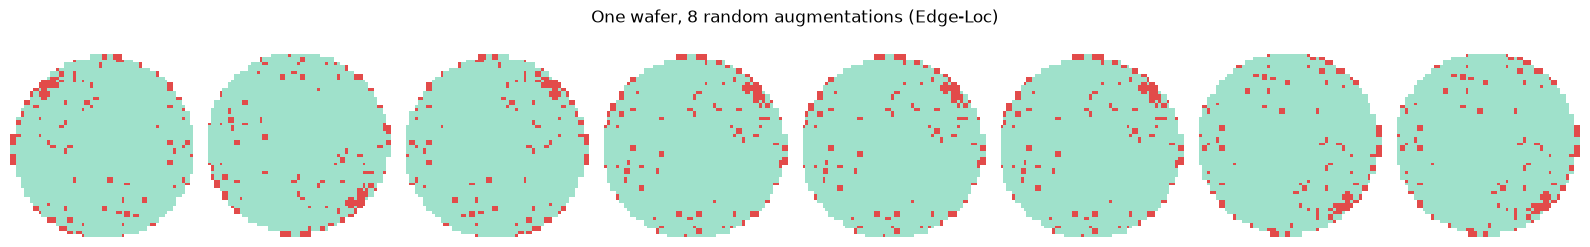

In [16]:
images, labels = next(iter(train_loader))
print('Images:', images.shape, images.dtype)   # expect (64, 1, 64, 64) float32
print('Labels:', labels.shape, labels.dtype)   # expect (64,) int64
print('Pixel values:', images.unique())        # expect 0.0, 0.5, 1.0

# Same wafer, augmented 8 times
WAFER_CMAP = ListedColormap(['white', '#9FE1CB', '#E24B4A'])
fig, axes = plt.subplots(1, 8, figsize=(16, 2.5))
for ax in axes:
    img, lbl = train_ds[0]                      # same index every time
    ax.imshow(img.squeeze(0), cmap=WAFER_CMAP, vmin=0, vmax=1, interpolation='nearest')
    ax.axis('off')
plt.suptitle(f'One wafer, 8 random augmentations ({CLASSES[lbl]})')
plt.tight_layout()
plt.show()

In [17]:
from src.classifier.model import WaferCNN

model = WaferCNN(num_classes=len(CLASSES)).to(device)

# How many numbers (weights) does the model learn?
n_params = sum(p.numel() for p in model.parameters())
print(f'Trainable parameters: {n_params:,}')

# Follow ONE wafer through every layer and print its shape
x = images[:1].to(device)
print(f'{"Input":15s} {tuple(x.shape)}')
for layer in model.features:
    x = layer(x)
    print(f'{layer.__class__.__name__:15s} {tuple(x.shape)}')
for layer in model.embedding:
    x = layer(x)
    print(f'{layer.__class__.__name__:15s} {tuple(x.shape)}')
x = model.classifier(x)
print(f'{"Classifier":15s} {tuple(x.shape)}')

Trainable parameters: 549,097
Input           (1, 1, 64, 64)
Conv2d          (1, 16, 64, 64)
BatchNorm2d     (1, 16, 64, 64)
ReLU            (1, 16, 64, 64)
MaxPool2d       (1, 16, 32, 32)
Conv2d          (1, 32, 32, 32)
BatchNorm2d     (1, 32, 32, 32)
ReLU            (1, 32, 32, 32)
MaxPool2d       (1, 32, 16, 16)
Conv2d          (1, 64, 16, 16)
BatchNorm2d     (1, 64, 16, 16)
ReLU            (1, 64, 16, 16)
MaxPool2d       (1, 64, 8, 8)
Flatten         (1, 4096)
Linear          (1, 128)
ReLU            (1, 128)
Dropout         (1, 128)
Classifier      (1, 9)


In [18]:
# One fixed batch, NO augmentation (so it's identical every step)
fixed_ds = WaferDataset(X_train[:64], y_train[:64], augment=False)
fixed_images, fixed_labels = next(iter(DataLoader(fixed_ds, batch_size=64)))
fixed_images, fixed_labels = fixed_images.to(device), fixed_labels.to(device)

model = WaferCNN(num_classes=len(CLASSES)).to(device)    # fresh model
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

model.train()
for step in range(1, 201):
    optimizer.zero_grad()                        # 1. clear old blame
    logits = model(fixed_images)                 # 2. guess
    loss = loss_fn(logits, fixed_labels)         # 3. grade
    loss.backward()                              # 4. blame (backprop)
    optimizer.step()                             # 5. adjust

    if step % 20 == 0:
        acc = (logits.argmax(dim=1) == fixed_labels).float().mean().item()
        print(f'Step {step:3d}  loss {loss.item():.4f}  accuracy {acc:.0%}')

Step  20  loss 0.2210  accuracy 95%
Step  40  loss 0.0220  accuracy 100%
Step  60  loss 0.0027  accuracy 100%
Step  80  loss 0.0070  accuracy 100%
Step 100  loss 0.0050  accuracy 100%
Step 120  loss 0.0023  accuracy 100%
Step 140  loss 0.0025  accuracy 100%
Step 160  loss 0.0037  accuracy 100%
Step 180  loss 0.0018  accuracy 100%
Step 200  loss 0.0025  accuracy 100%
